<a href="https://colab.research.google.com/github/esneydersandoval31-alt/608142-DEEP-LEARNING--CONCEPTOS/blob/main/R2_A3_S12_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Forma X_train: (1370, 30, 1) | Forma y_train: (1370, 1)

Resultados en Prueba (Escala Original):
Modelo con Atención -> MSE: 0.4466 | MAE: 0.5451
Modelo Transformer  -> MSE: 0.9848 | MAE: 0.8137


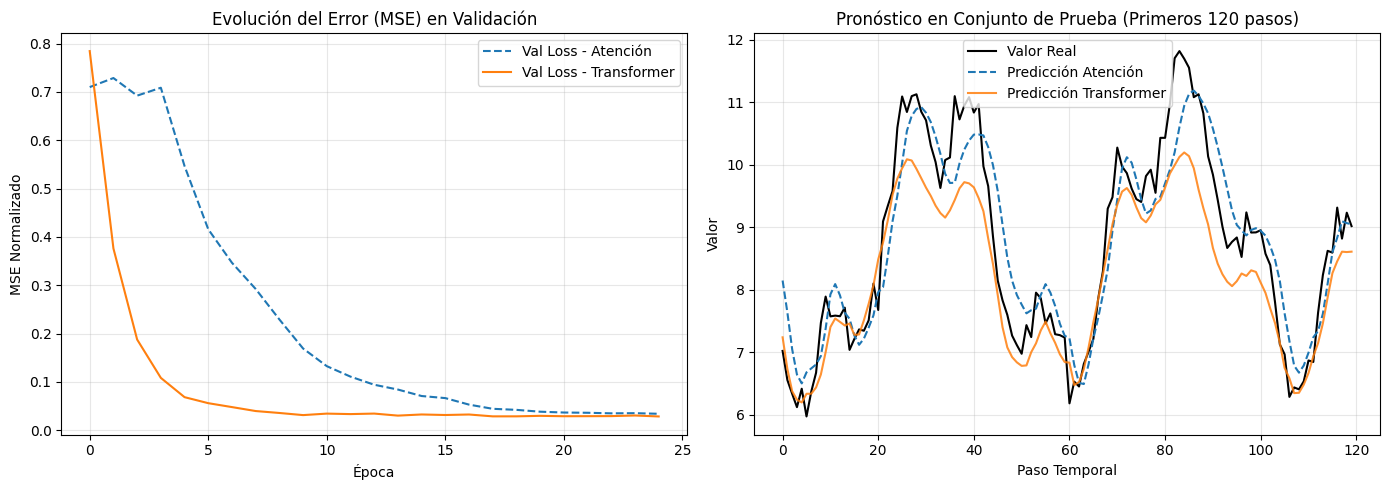

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Fijar semillas para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# ==============================================================================
# 1. PREPARACIÓN Y PREPROCESAMIENTO DE LA SERIE DE TIEMPO
# ==============================================================================
def generar_serie_tiempo(n_pasos=2000):
    tiempo = np.arange(n_pasos)
    # Combinación de tendencia lineal, dos ciclos estacionales y ruido gaussiano
    tendencia = 0.005 * tiempo
    estacionalidad_1 = 2.0 * np.sin(2 * np.pi * tiempo / 50.0)
    estacionalidad_2 = 0.8 * np.cos(2 * np.pi * tiempo / 15.0)
    ruido = np.random.normal(0, 0.25, size=n_pasos)
    serie = tendencia + estacionalidad_1 + estacionalidad_2 + ruido
    return serie.astype(np.float32)

serie = generar_serie_tiempo()

# División cronológica (70% entrenamiento, 15% validación, 15% prueba)
n = len(serie)
train_data = serie[:int(n * 0.7)]
val_data = serie[int(n * 0.7):int(n * 0.85)]
test_data = serie[int(n * 0.85):]

# Normalización Z-score usando solo estadísticas de entrenamiento (evita fuga de datos)
media = train_data.mean()
std = train_data.std()

train_norm = (train_data - media) / std
val_norm = (val_data - media) / std
test_norm = (test_data - media) / std

def crear_ventanas(datos, ventana_entrada=30):
    X, y = [], []
    for i in range(len(datos) - ventana_entrada):
        X.append(datos[i : i + ventana_entrada])
        y.append(datos[i + ventana_entrada])
    X = np.array(X)[..., np.newaxis]  # Forma: (muestras, pasos, 1 característica)
    y = np.array(y)[..., np.newaxis]  # Forma: (muestras, 1)
    return X, y

VENTANA = 30
X_train, y_train = crear_ventanas(train_norm, VENTANA)
X_val, y_val = crear_ventanas(val_norm, VENTANA)
X_test, y_test = crear_ventanas(test_norm, VENTANA)

print(f"Forma X_train: {X_train.shape} | Forma y_train: {y_train.shape}")

# ==============================================================================
# 2. MODELO 1: MECANISMO DE ATENCIÓN APLICADO A SERIE DE TIEMPO (Bahdanau/Luong)
# ==============================================================================
class CapaAtencionTemporal(layers.Layer):
    """Calcula pesos de atención sobre los estados ocultos de cada paso temporal."""
    def __init__(self, unidades):
        super().__init__()
        self.W = layers.Dense(unidades, activation="tanh")
        self.V = layers.Dense(1)

    def call(self, secuencia_estados):
        # secuencia_estados: (batch, pasos, caracteristicas)
        puntajes = self.V(self.W(secuencia_estados))        # (batch, pasos, 1)
        pesos_atencion = tf.nn.softmax(puntajes, axis=1)    # Distribución de probabilidad temporal
        vector_contexto = tf.reduce_sum(pesos_atencion * secuencia_estados, axis=1)
        return vector_contexto, pesos_atencion

def construir_modelo_atencion(forma_entrada):
    entradas = keras.Input(shape=forma_entrada)
    # Extracción inicial de representaciones secuenciales
    secuencia = layers.GRU(32, return_sequences=True)(entradas)
    contexto, _ = CapaAtencionTemporal(32)(secuencia)
    salidas = layers.Dense(1)(contexto)
    modelo = keras.Model(inputs=entradas, outputs=salidas, name="Modelo_Atencion_SerieTiempo")
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return modelo

modelo_atencion = construir_modelo_atencion((VENTANA, 1))
hist_atencion = modelo_atencion.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25, batch_size=32, verbose=0
)

# ==============================================================================
# 3. MODELO 2: ARQUITECTURA TRANSFORMER BÁSICA (Vaswani et al., 2017)
# ==============================================================================
class CodificacionPosicional(layers.Layer):
    """Inyecta información del orden temporal mediante funciones seno y coseno."""
    def __init__(self, longitud_max, d_model):
        super().__init__()
        posiciones = np.arange(longitud_max)[:, np.newaxis]
        dimensiones = np.arange(d_model)[np.newaxis, :]
        angulos = posiciones / np.power(10000, (2 * (dimensiones // 2)) / np.float32(d_model))

        angulos[:, 0::2] = np.sin(angulos[:, 0::2])
        angulos[:, 1::2] = np.cos(angulos[:, 1::2])
        self.pos_encoding = tf.cast(angulos[np.newaxis, ...], dtype=tf.float32)

    def call(self, x):
        return x + self.pos_encoding[:, :tf.shape(x)[1], :]

def bloque_encoder_transformer(entradas, d_model, num_cabezas, d_ff, dropout=0.1):
    # 1. Multi-Head Self-Attention + Conexión Residual + LayerNorm
    atencion = layers.MultiHeadAttention(
        num_heads=num_cabezas, key_dim=d_model // num_cabezas, dropout=dropout
    )(entradas, entradas)
    atencion = layers.Dropout(dropout)(atencion)
    out_1 = layers.LayerNormalization(epsilon=1e-6)(entradas + atencion)

    # 2. Red Feed-Forward puntual + Conexión Residual + LayerNorm
    ffn = keras.Sequential([
        layers.Dense(d_ff, activation="relu"),
        layers.Dense(d_model)
    ])
    salida_ffn = ffn(out_1)
    salida_ffn = layers.Dropout(dropout)(salida_ffn)
    out_2 = layers.LayerNormalization(epsilon=1e-6)(out_1 + salida_ffn)
    return out_2

def construir_transformer(forma_entrada, d_model=32, num_cabezas=4, d_ff=64):
    entradas = keras.Input(shape=forma_entrada)
    # Proyección lineal (Embedding continuo para variables numéricas)
    x = layers.Dense(d_model)(entradas)
    x = CodificacionPosicional(forma_entrada[0], d_model)(x)

    # Dos bloques Encoder apilados
    x = bloque_encoder_transformer(x, d_model, num_cabezas, d_ff)
    x = bloque_encoder_transformer(x, d_model, num_cabezas, d_ff)

    # Agregación global y capa de predicción
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(16, activation="relu")(x)
    salidas = layers.Dense(1)(x)

    modelo = keras.Model(inputs=entradas, outputs=salidas, name="Transformer_Basico")
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return modelo

modelo_transformer = construir_transformer((VENTANA, 1))
hist_transformer = modelo_transformer.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25, batch_size=32, verbose=0
)

# ==============================================================================
# 4. EVALUACIÓN Y VISUALIZACIÓN DE RESULTADOS
# ==============================================================================
def evaluar_modelo(modelo, X, y_real_norm):
    pred_norm = modelo.predict(X, verbose=0)
    # Desnormalizar para interpretar en escala original
    pred = pred_norm * std + media
    real = y_real_norm * std + media
    mse = mean_squared_error(real, pred)
    mae = mean_absolute_error(real, pred)
    return pred, real, mse, mae

pred_att, real, mse_att, mae_att = evaluar_modelo(modelo_atencion, X_test, y_test)
pred_tra, _, mse_tra, mae_tra = evaluar_modelo(modelo_transformer, X_test, y_test)

print(f"\nResultados en Prueba (Escala Original):")
print(f"Modelo con Atención -> MSE: {mse_att:.4f} | MAE: {mae_att:.4f}")
print(f"Modelo Transformer  -> MSE: {mse_tra:.4f} | MAE: {mae_tra:.4f}")

# Gráficas de pérdida y predicción
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_atencion.history["val_loss"], label="Val Loss - Atención", linestyle="--")
axes[0].plot(hist_transformer.history["val_loss"], label="Val Loss - Transformer")
axes[0].set_title("Evolución del Error (MSE) en Validación")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MSE Normalizado")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(real[:120], label="Valor Real", color="black", linewidth=1.5)
axes[1].plot(pred_att[:120], label="Predicción Atención", linestyle="--")
axes[1].plot(pred_tra[:120], label="Predicción Transformer", alpha=0.85)
axes[1].set_title("Pronóstico en Conjunto de Prueba (Primeros 120 pasos)")
axes[1].set_xlabel("Paso Temporal")
axes[1].set_ylabel("Valor")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Entrenando: Transformer (2 cabezas)...
Entrenando: Transformer (4 cabezas, Original)...
Entrenando: Transformer (8 cabezas, Mayor Capacidad)...

--- Resultados comparativos en Prueba ---
Transformer (2 cabezas) -> MSE: 0.3774 | MAE: 0.5137
Transformer (4 cabezas, Original) -> MSE: 0.4173 | MAE: 0.5176
Transformer (8 cabezas, Mayor Capacidad) -> MSE: 0.8245 | MAE: 0.6743


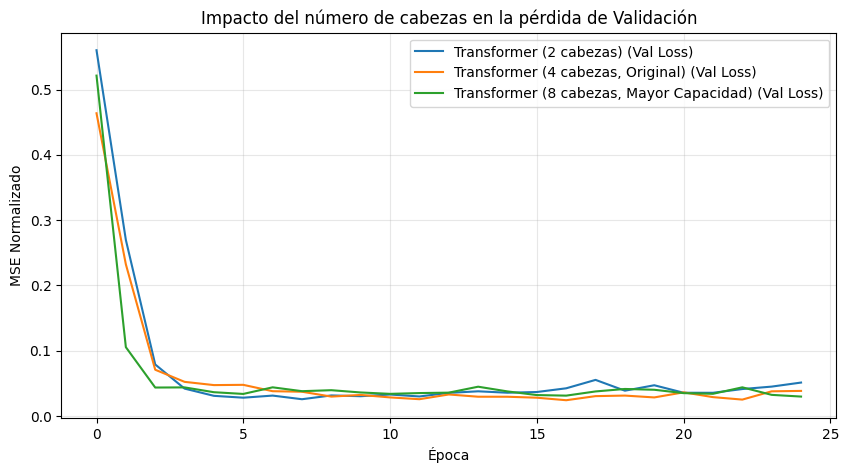

In [2]:
import matplotlib.pyplot as plt

# Vamos a probar con diferentes combinaciones de cabezas
# Para mantener una proporción saludable, aumentamos ligeramente d_model si usamos más cabezas
configuraciones = [
    {"d_model": 32, "num_cabezas": 2, "d_ff": 64, "nombre": "Transformer (2 cabezas)"},
    {"d_model": 32, "num_cabezas": 4, "d_ff": 64, "nombre": "Transformer (4 cabezas, Original)"},
    {"d_model": 64, "num_cabezas": 8, "d_ff": 128, "nombre": "Transformer (8 cabezas, Mayor Capacidad)"}
]

resultados_experimento = {}

for config in configuraciones:
    print(f"Entrenando: {config['nombre']}...")
    modelo_temp = construir_transformer(
        forma_entrada=(VENTANA, 1),
        d_model=config["d_model"],
        num_cabezas=config["num_cabezas"],
        d_ff=config["d_ff"]
    )

    hist = modelo_temp.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=25, batch_size=32, verbose=0
    )

    pred, _, mse_test, mae_test = evaluar_modelo(modelo_temp, X_test, y_test)

    resultados_experimento[config["nombre"]] = {
        "historial": hist.history["val_loss"],
        "mse": mse_test,
        "mae": mae_test,
        "pred": pred
    }

# Imprimir métricas finales comparativas
print("\n--- Resultados comparativos en Prueba ---")
for nombre, datos in resultados_experimento.items():
    print(f"{nombre} -> MSE: {datos['mse']:.4f} | MAE: {datos['mae']:.4f}")

# Graficar la evolución de la pérdida de validación para cada configuración
plt.figure(figsize=(10, 5))
for nombre, datos in resultados_experimento.items():
    plt.plot(datos["historial"], label=f"{nombre} (Val Loss)")
plt.title("Impacto del número de cabezas en la pérdida de Validación")
plt.xlabel("Época")
plt.ylabel("MSE Normalizado")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Entrenando: Transformer 8H (Dropout 0.1 - Original)...
Entrenando: Transformer 8H (Dropout 0.3)...
Entrenando: Transformer 8H (Dropout 0.5)...

--- Resultados comparativos con regularización por Dropout ---
Transformer 8H (Dropout 0.1 - Original) -> MSE: 1.1037 | MAE: 0.7919
Transformer 8H (Dropout 0.3) -> MSE: 1.0961 | MAE: 0.8844
Transformer 8H (Dropout 0.5) -> MSE: 3.4052 | MAE: 1.7995


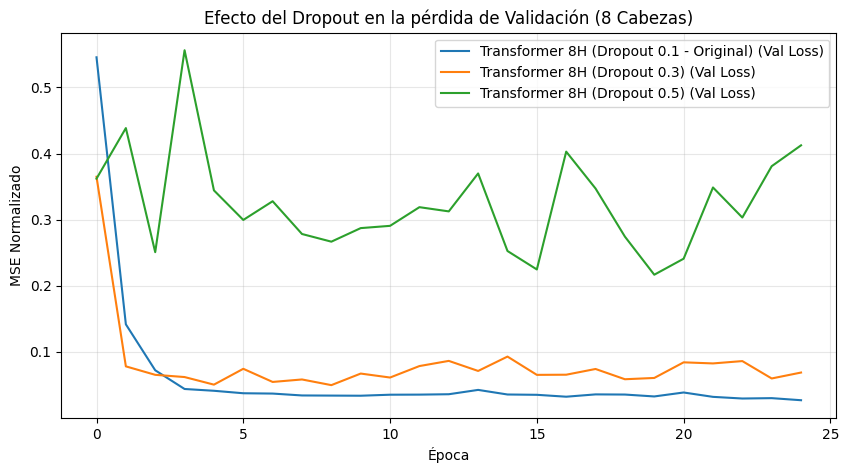

In [3]:
# Modificamos la función para que acepte dropout de forma dinámica al construir el modelo
def construir_transformer_con_dropout(forma_entrada, d_model=64, num_cabezas=8, d_ff=128, dropout_rate=0.1):
    entradas = keras.Input(shape=forma_entrada)
    x = layers.Dense(d_model)(entradas)
    x = CodificacionPosicional(forma_entrada[0], d_model)(x)

    # Dos bloques Encoder apilados con el dropout especificado
    x = bloque_encoder_transformer(x, d_model, num_cabezas, d_ff, dropout=dropout_rate)
    x = bloque_encoder_transformer(x, d_model, num_cabezas, d_ff, dropout=dropout_rate)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(16, activation="relu")(x)
    salidas = layers.Dense(1)(x)

    modelo = keras.Model(inputs=entradas, outputs=salidas, name=f"Transformer_8H_Dropout_{dropout_rate}")
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])
    return modelo

# Configuraciones a evaluar
experimentos_dropout = [
    {"dropout": 0.1, "nombre": "Transformer 8H (Dropout 0.1 - Original)"},
    {"dropout": 0.3, "nombre": "Transformer 8H (Dropout 0.3)"},
    {"dropout": 0.5, "nombre": "Transformer 8H (Dropout 0.5)"}
]

resultados_dropout = {}

for exp in experimentos_dropout:
    print(f"Entrenando: {exp['nombre']}...")
    modelo_drop = construir_transformer_con_dropout(
        forma_entrada=(VENTANA, 1),
        d_model=64,
        num_cabezas=8,
        d_ff=128,
        dropout_rate=exp["dropout"]
    )

    hist = modelo_drop.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=25, batch_size=32, verbose=0
    )

    pred, _, mse_test, mae_test = evaluar_modelo(modelo_drop, X_test, y_test)

    resultados_dropout[exp["nombre"]] = {
        "historial": hist.history["val_loss"],
        "mse": mse_test,
        "mae": mae_test
    }

# Resultados finales
print("\n--- Resultados comparativos con regularización por Dropout ---")
for nombre, datos in resultados_dropout.items():
    print(f"{nombre} -> MSE: {datos['mse']:.4f} | MAE: {datos['mae']:.4f}")

# Graficar curvas de pérdida de validación
plt.figure(figsize=(10, 5))
for nombre, datos in resultados_dropout.items():
    plt.plot(datos["historial"], label=f"{nombre} (Val Loss)")
plt.title("Efecto del Dropout en la pérdida de Validación (8 Cabezas)")
plt.xlabel("Época")
plt.ylabel("MSE Normalizado")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()